In [10]:
!pip install scikit-learn Pillow numpy pandas matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
#3.1 VECTORISING TEXT, TRANSFORMING 3 SAMPLE DOCS INTO A MATRIX WHERE DOC = ROW AND
#  COLUMN = 1 UNIQUE WORD (FEATURE) 
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Define Sample Text Data (our "corpus")
documents = [
    "The sun is shining today.",
    "The weather is good, the sun is great.",
    "A sunny day is a wonderful day."
]

print("--- Raw Text Documents ---")
for i, doc in enumerate(documents):
    print(f"Doc {i+1}: {doc}")

--- Raw Text Documents ---
Doc 1: The sun is shining today.
Doc 2: The weather is good, the sun is great.
Doc 3: A sunny day is a wonderful day.


In [12]:
# 2. Apply Feature Engineering: CountVectorizer (Bag-of-Words)
#    CountVectorizer performs tokenization AND vocabulary building in one step.
vectorizer = CountVectorizer()

# fit_transform learns the vocabulary and converts the documents into feature vectors
X_text = vectorizer.fit_transform(documents)

# 3. Analyze the Results
feature_names = vectorizer.get_feature_names_out()
text_matrix = X_text.toarray()

print("--- Bag-of-Words (BoW) Transformation ---")
print(f"Vocabulary (Features): {feature_names}")
print(f"Shape of Feature Matrix: {text_matrix.shape}   (documents x unique terms)")

--- Bag-of-Words (BoW) Transformation ---
Vocabulary (Features): ['day' 'good' 'great' 'is' 'shining' 'sun' 'sunny' 'the' 'today' 'weather'
 'wonderful']
Shape of Feature Matrix: (3, 11)   (documents x unique terms)


In [13]:
# A DataFrame view, purely so the matrix is readable
df_text = pd.DataFrame(text_matrix, columns=feature_names,
                       index=[f"Doc {i+1}" for i in range(len(documents))])

print("BoW Numerical Feature Matrix (Machine Understandable Format):\n")
display(df_text)

BoW Numerical Feature Matrix (Machine Understandable Format):



,day,good,great,is,shining,sun,sunny,the,today,weather,wonderful
Doc 1,0,0,0,1,1,1,0,1,1,0,0
Doc 2,0,1,1,2,0,1,0,2,0,1,0
Doc 3,2,0,0,1,0,0,1,0,0,0,1


> `CountVectorizer` **lowercases** every token by default, so *The* and *the* collapse into one
> feature; and its default token pattern **discards single-character tokens**, so the *"a"* of
> Document 3 never enters the vocabulary. Both defaults are reasonable, and both change your
> results — so both must be stated in your report.

In [14]:
# Prove the two silent decisions to yourself rather than taking them on trust.

print("Is 'a' in the vocabulary? ", 'a' in feature_names)
print("Is 'the' in the vocabulary?", 'the' in feature_names)
print()
print("Default token pattern :", vectorizer.token_pattern)
print("Lowercase enabled     :", vectorizer.lowercase)
print()
print("The token pattern requires 2+ word characters, which is why 'a' is dropped.")

Is 'a' in the vocabulary?  False
Is 'the' in the vocabulary? True

Default token pattern : (?u)\b\w\w+\b
Lowercase enabled     : True

The token pattern requires 2+ word characters, which is why 'a' is dropped.


In [15]:
# Sparsity: how much of this matrix is zero? This is the defining property of BoW.
total_cells = text_matrix.size
zero_cells = (text_matrix == 0).sum()

print(f"Matrix cells : {total_cells}")
print(f"Zero cells   : {zero_cells}")
print(f"Sparsity     : {zero_cells / total_cells:.1%}")
print()
print("With a real corpus of 20,000 documents this figure exceeds 99%,")
print("which is why scikit-learn returns a SPARSE matrix, not a dense array.")
print("Type returned by fit_transform:", type(X_text))

Matrix cells : 33
Zero cells   : 18
Sparsity     : 54.5%

With a real corpus of 20,000 documents this figure exceeds 99%,
which is why scikit-learn returns a SPARSE matrix, not a dense array.
Type returned by fit_transform: <class 'scipy.sparse._csr.csr_matrix'>


## Discussion questions (Part A)

Answer these in the Markdown cell below.

1. What does each **column** in the resulting matrix represent?
2. In this specific numerical matrix, what is the *machine-understandable format*?
3. How is this format an **oversimplification** of the original text data? (Consider what information has been lost.)

**Your answers (Part A):**

1. Each column in the resulting matrix represents a unique word from the dictionary.

2. The matrix contains word frequency counts where the numbers indicate how many times that unique word appeared in the document / sentence

3. this format is an oversimplification because the Bag-of-Words model completely ignores grammar and word order. Because structural and sequential context is thrown away, sentences with completely different meanings (such as "Dog bites man" versus "Man bites dog") are treated by the computer as the exact same collection of words since their individual word counts are identical.

---

In [18]:
!pip install gdown
!pip install opencv-python


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 2.3 MB/s eta 0:00:19
   - -------------------------------------- 2.1/44.0 MB 3.4 MB/s eta 0:00:13
   ---- ----------------------------------- 4.7/44.0 MB 5.8 MB/s eta 0:00:07
   ------- -------------------------------- 8.1/44.0 MB 8.0 MB/s eta 0:00:05
   -------- ------------------------------- 9.4/44.0 MB 8.6 MB/s eta 0:00:05
   -------- ------------------------------- 9.4/44.0 MB 8.6 MB/s eta 0:00:05
   -------- ------------------------------- 9.4/44.0 MB 8.6 MB/s eta 0:00:05
   -------- ------------------------------- 9.4/44.0 MB 8.6 MB/s eta 0:00:05
   -------- ------------------------------- 9.7/44.0 MB 5.1 MB/s eta 0:00:07
   -------- ---------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import numpy as np
from PIL import Image
import os
import cv2

# Simply point directly to the file name in the current folder
image_file_path = 'smiski.jpg'

# 1. Load Image or Create a Dummy Image
original_image = None
if image_file_path and os.path.exists(image_file_path):
    try:
        original_image = Image.open(image_file_path)
        print(f"--- Loaded Image from File: {image_file_path} ---")
    except Exception as e:
        print(f"Error loading image from {image_file_path}: {e}")
        dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
        original_image = Image.fromarray(dummy, 'RGB')
        print("--- Created Dummy Image (100x100 RGB) ---")
else:
    print("No valid image file path provided or file not found.")
    dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
    original_image = Image.fromarray(dummy, 'RGB')
    print("--- Created Dummy Image (100x100 RGB) ---")

# Ensure a consistent 3-channel representation
original_image = original_image.convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

No valid image file path provided or file not found.
--- Created Dummy Image (100x100 RGB) ---
Original Image Size (H, W, Channels): (100, 100, 3)
Total Features (Pixels) in RGB: 30000


In [ ]:
# 2. Feature Engineering step 1: Grayscale Conversion ('L' mode = luminance)
grayscale_image = original_image.convert('L')
grayscale_array = np.array(grayscale_image)

print("--- Grayscale Conversion (Feature Reduction) ---")
print(f"Grayscale Image Size (H, W): {grayscale_array.shape}")
print(f"Total Features (Pixels) after Grayscale: {grayscale_array.size}")
print()
print(f"Reduction factor: {(h * w * c) / grayscale_array.size:.0f}x fewer features")

--- Grayscale Conversion (Feature Reduction) ---
Grayscale Image Size (H, W): (678, 452)
Total Features (Pixels) after Grayscale: 306456

Reduction factor: 3x fewer features


In [ ]:
# 3. Feature Engineering step 2: Pixel Flattening (2D matrix -> 1D vector)
flattened_features = grayscale_array.flatten()

print("--- Pixel Flattening (Vectorization) ---")
print(f"Flattened Feature Vector Shape: {flattened_features.shape}")
print()
print("First 10 Features (Pixel Values) in Machine Understandable Format:")
print(flattened_features[:10])
print()
print(f"Data Type of Final Features: {flattened_features.dtype}")

--- Pixel Flattening (Vectorization) ---
Flattened Feature Vector Shape: (306456,)

First 10 Features (Pixel Values) in Machine Understandable Format:
[53 51 47 43 38 33 30 28 27 27]

Data Type of Final Features: uint8


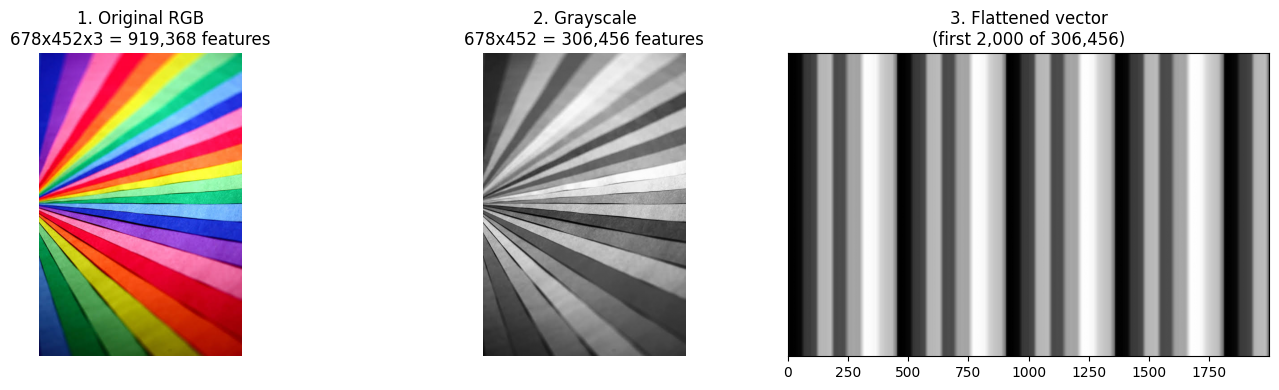

In [ ]:
# Show all three stages side by side so the loss of information is visible.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(original_image)
axes[0].set_title(f"1. Original RGB\n{h}x{w}x{c} = {h*w*c:,} features")
axes[0].axis('off')

axes[1].imshow(grayscale_image, cmap='gray')
axes[1].set_title(f"2. Grayscale\n{h}x{w} = {h*w:,} features")
axes[1].axis('off')

# A 1-D vector drawn as a single row of pixels
axes[2].imshow(flattened_features[:2000].reshape(1, -1), cmap='gray', aspect='auto')
axes[2].set_title(f"3. Flattened vector\n(first 2,000 of {flattened_features.size:,})")
axes[2].set_yticks([])

plt.tight_layout()
plt.show()

 ### Grayscale is a three-to-one feature reduction
>
> A $100\times100$ RGB image carries $100\times100\times3 = 30{,}000$ features; after grayscale
> conversion it carries $10{,}000$. **Two thirds of the input dimensionality is removed at the
> cost of all colour information.** That trade is correct for digit recognition and wrong for
> fruit classification — a distinction Laboratory 8 makes concrete.

---
# In-Lab Exercises

**Exercise 1.** Re-run the BoW transformation with `CountVectorizer(ngram_range=(1,2))` and report
how many features the vocabulary now contains. Explain the growth.

**Exercise 2.** Add a fourth document that repeats the word *sun* five times. Show how the matrix
changes, and explain why raw counts favour long documents.

**Exercise 3.** Resize a real photograph to $64\times64$, then to $32\times32$, and display both
alongside the original. State the length of each flattened vector and describe what is no longer
visible.

**Exercise 4.** Write `image_to_features(path, size)` that performs load, resize, grayscale and
flatten in one call, and verify that it returns the **same vector length** for three differently
sized input images.

In [ ]:
# --- Exercise 1: unigrams + bigrams --------------------------------------

vec_1gram = CountVectorizer(ngram_range=(1, 1))
vec_2gram = CountVectorizer(ngram_range=(1, 2))

X1 = vec_1gram.fit_transform(documents)
X2 = vec_2gram.fit_transform(documents)

print(f"ngram_range=(1,1) -> {X1.shape[1]:3d} features")
print(f"ngram_range=(1,2) -> {X2.shape[1]:3d} features")
print(f"Growth factor     : {X2.shape[1] / X1.shape[1]:.1f}x")
print()
print("New bigram features introduced:")
print([f for f in vec_2gram.get_feature_names_out() if ' ' in f])

ngram_range=(1,1) ->  11 features
ngram_range=(1,2) ->  24 features
Growth factor     : 2.2x

New bigram features introduced:
['day is', 'good the', 'is good', 'is great', 'is shining', 'is wonderful', 'shining today', 'sun is', 'sunny day', 'the sun', 'the weather', 'weather is', 'wonderful day']


In [ ]:
# --- Exercise 2: raw counts favour long documents ------------------------

documents_4 = documents + ["sun sun sun sun sun and more sun today"]

vec = CountVectorizer()
M = vec.fit_transform(documents_4).toarray()
df4 = pd.DataFrame(M, columns=vec.get_feature_names_out(),
                   index=[f"Doc {i+1}" for i in range(len(documents_4))])
display(df4)

print("Total token count per document (row sums):")
print(df4.sum(axis=1).to_string())
print()
print("Doc 4 dominates the 'sun' column purely by repetition.")
print("This is exactly the problem TF-IDF (Lab 02) was designed to correct.")

,and,day,good,great,is,more,shining,sun,sunny,the,today,weather,wonderful
Doc 1,0,0,0,0,1,0,1,1,0,1,1,0,0
Doc 2,0,0,1,1,2,0,0,1,0,2,0,1,0
Doc 3,0,2,0,0,1,0,0,0,1,0,0,0,1
Doc 4,1,0,0,0,0,1,0,6,0,0,1,0,0


Total token count per document (row sums):
Doc 1    5
Doc 2    8
Doc 3    5
Doc 4    9

Doc 4 dominates the 'sun' column purely by repetition.
This is exactly the problem TF-IDF (Lab 02) was designed to correct.


In [ ]:
# --- Exercise 4: a reusable image -> feature-vector function -------------

def image_to_features(path, size=(64, 64)):
    """Load, resize, grayscale and flatten an image into a 1-D feature vector.

    Parameters
    ----------
    path : str
        Path to an image file.
    size : tuple[int, int]
        Target (width, height). Every image is forced to this size so that
        every returned vector has the SAME length -- which is what a model
        with a fixed input layer requires.

    Returns
    -------
    numpy.ndarray of shape (size[0] * size[1],), dtype uint8
    """
    img = Image.open(path).convert("RGB")   # normalise channel count first
    img = img.resize(size)                  # then normalise dimensions
    img = img.convert("L")                  # then reduce to one channel
    return np.array(img).flatten()          # finally vectorise


# Verify the guarantee on three differently sized synthetic images.
os.makedirs("test_images", exist_ok=True)
for i, dims in enumerate([(120, 80), (300, 300), (64, 200)], start=1):
    arr = np.random.randint(0, 256, size=(dims[1], dims[0], 3), dtype=np.uint8)
    Image.fromarray(arr, "RGB").save(f"test_images/img{i}.png")

for i, dims in enumerate([(120, 80), (300, 300), (64, 200)], start=1):
    v = image_to_features(f"test_images/img{i}.png", size=(64, 64))
    print(f"img{i}.png  original {dims[0]}x{dims[1]}  ->  vector length {v.shape[0]}")

print("\nAll three vectors have identical length -- the model can accept any of them.")

img1.png  original 120x80  ->  vector length 4096
img2.png  original 300x300  ->  vector length 4096
img3.png  original 64x200  ->  vector length 4096

All three vectors have identical length -- the model can accept any of them.


/tmp/ipykernel_790/3926732397.py:29: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(arr, "RGB").save(f"test_images/img{i}.png")


In [ ]:
# --- Home assignment scaffold --------------------------------------------
# Put your images in  data/class_a/  and  data/class_b/  then run this cell.

from glob import glob

CLASS_DIRS = {0: "data/class_a", 1: "data/class_b"}
SIZE = (64, 64)

X_list, y_list = [], []
for label, folder in CLASS_DIRS.items():
    paths = sorted(glob(os.path.join(folder, "*")))
    for p in paths:
        try:
            X_list.append(image_to_features(p, size=SIZE))
            y_list.append(label)
        except Exception as e:
            print(f"[SKIP] {p} -> {e}")

if X_list:
    X = np.vstack(X_list)
    y = np.array(y_list)
    np.savez("dataset.npz", X=X, y=y)

    print(f"X shape: {X.shape}   y shape: {y.shape}")
    print(f"Samples: {X.shape[0]}   Features per sample: {X.shape[1]}")
    print(f"Samples per feature: {X.shape[0] / X.shape[1]:.4f}")
    print()
    print("Saved dataset.npz")
else:
    print("No images found. Create data/class_a and data/class_b and add images.")

No images found. Create data/class_a and data/class_b and add images.
